# Пример 13. Нулевые пространства и пересечение

## Тема

**Раздел книги:** Линейная алгебра.  
**Математическая тема:** нулевое пространство (ядро) матрицы, теорема о ранге и дефекте $\dim\ker A = n - \operatorname{rank}A$, базисы пространств решений, пересечение ядер как ядро блочной матрицы $\begin{bmatrix}A_1\\A_2\end{bmatrix}$; связь с неразличимостью (unidentifiability) параметров в линейных моделях и с выравниванием представлений (representation alignment) в ML.

## Условие
Даны два подпространства $\mathbb{R}^3$: $U_1$ — пространство решений однородной системы $A_1 x = 0$, $U_2$ — пространство решений $A_2 x = 0$, где
$$
A_1 = \begin{bmatrix}1&0&1\\1&-2&-1\\2&1&3\\1&0&1\end{bmatrix},\qquad
A_2 = \begin{bmatrix}3&-3&0\\1&2&3\\7&-5&2\\3&-1&2\end{bmatrix}.
$$
Требуется: **(a)** определить $\dim U_1,\dim U_2$; **(b)** найти базисы $U_1,U_2$; **(c)** найти базис $U_1\cap U_2$.

## Математическая идея
Пространство решений $A x = 0$ — это **ядро** $\ker A$. По теореме о ранге и дефекте для $A\in\mathbb{R}^{m\times n}$:
$$
\dim\ker A = n - \operatorname{rank}A.
$$
Вектор $x$ лежит в $U_1\cap U_2$ тогда и только тогда, когда он удовлетворяет **обеим** системам, то есть $x\in\ker\begin{bmatrix}A_1\\A_2\end{bmatrix}$ (стопка строк). Ядро удобно находить через **SVD**: если $\operatorname{rank}A = r$, то базис $\ker A$ — это строки $V^\top$ с индексами $r,\dots,n-1$.

Отдельно заметим геометрический факт: $\ker A = (\operatorname{row}A)^\perp$. Если у $A_1$ и $A_2$ совпадают пространства строк, то совпадают и их ядра — и тогда $U_1\cap U_2 = U_1 = U_2$.

## Решение

**(a) Размерности.** Приведём $A_1$ к ступенчатому виду (строка 4 = строка 1):
$$
\begin{bmatrix}1&0&1\\1&-2&-1\\2&1&3\\1&0&1\end{bmatrix}\to
\begin{bmatrix}1&0&1\\0&-2&-2\\0&1&1\\0&0&0\end{bmatrix}\to
\begin{bmatrix}1&0&1\\0&1&1\\0&0&0\\0&0&0\end{bmatrix},\quad \operatorname{rank}A_1=2.
$$
Для $A_2$ (переставив строки):
$$
\begin{bmatrix}1&2&3\\3&-3&0\\7&-5&2\\3&-1&2\end{bmatrix}\to
\begin{bmatrix}1&2&3\\0&-9&-9\\0&-19&-19\\0&-7&-7\end{bmatrix}\to
\begin{bmatrix}1&2&3\\0&1&1\\0&0&0\\0&0&0\end{bmatrix},\quad \operatorname{rank}A_2=2.
$$
Отсюда $\dim U_1 = 3-2 = \boxed{1}$, $\dim U_2 = 3-2 = \boxed{1}$.

**(b) Базисы.** Из редуцированной $A_1$: $x_1+x_3=0,\ x_2+x_3=0 \Rightarrow x = t(1,1,-1)^\top$.
Из редуцированной $A_2$: $x_2+x_3=0,\ x_1+2x_2+3x_3=0 \Rightarrow x_1=-x_3,\ x_2=-x_3 \Rightarrow x = t(1,1,-1)^\top$.
$$
\text{Базис }U_1 = \left\{\begin{bmatrix}1\\1\\-1\end{bmatrix}\right\},\qquad
\text{Базис }U_2 = \left\{\begin{bmatrix}1\\1\\-1\end{bmatrix}\right\}.
$$
Проверка подстановкой в исходные строки $A_1,A_2$ даёт нули.

**(c) Пересечение.** Так как $U_1 = U_2 = \operatorname{span}\{(1,1,-1)^\top\}$, то
$$
U_1\cap U_2 = \operatorname{span}\left\{\begin{bmatrix}1\\1\\-1\end{bmatrix}\right\},\qquad \dim(U_1\cap U_2)=1.
$$
Контроль через стопку: $\operatorname{rank}\begin{bmatrix}A_1\\A_2\end{bmatrix}=2$ (пространства строк совпадают), значит $\dim\ker = 3-2 = 1$ — согласуется.

**Итог:** $U_1=U_2=U_1\cap U_2$ — одна и та же прямая в $\mathbb{R}^3$.

In [1]:
import numpy as np

A1 = np.array([[1, 0, 1],
              [1, -2, -1],
              [2, 1, 3],
              [1, 0, 1]], dtype=float)

A2 = np.array([[3, -3, 0],
              [1, 2, 3],
              [7, -5, 2],
              [3, -1, 2]], dtype=float)

def null_space(A, tol=1e-10):
    """Базис ядра через SVD: строки Vh с индекса rank(A)."""
    _, s, Vh = np.linalg.svd(A)
    r = np.linalg.matrix_rank(A, tol=tol)
    return Vh[r:].T, r

N1, r1 = null_space(A1)
N2, r2 = null_space(A2)
print(f"(a) rank(A1)={r1} -> dim U1={3-r1}; rank(A2)={r2} -> dim U2={3-r2}")
print(f"(b) базис U1 (столбцы):\n{np.round(N1,6)}")
print(f"    базис U2 (столбцы):\n{np.round(N2,6)}")

# (c) пересечение = ядро стопки [A1; A2]
Nint, rint = null_space(np.vstack([A1, A2]))
print(f"(c) rank([A1;A2])={rint} -> dim(U1∩U2)={3-rint}")
print(f"    базис (U1∩U2):\n{np.round(Nint,6)}")

# Прямая проверка: вектор пересечения обнуляет обе матрицы
v = Nint[:, 0]
print("||A1 v|| =", np.linalg.norm(A1 @ v), "| ||A2 v|| =", np.linalg.norm(A2 @ v))

(a) rank(A1)=2 -> dim U1=1; rank(A2)=2 -> dim U2=1
(b) базис U1 (столбцы):
[[ 0.57735]
 [ 0.57735]
 [-0.57735]]
    базис U2 (столбцы):
[[ 0.57735]
 [ 0.57735]
 [-0.57735]]
(c) rank([A1;A2])=2 -> dim(U1∩U2)=1
    базис (U1∩U2):
[[ 0.57735]
 [ 0.57735]
 [-0.57735]]
||A1 v|| = 3.6821932062951477e-16 | ||A2 v|| = 1.6050308076832566e-15


## Дополнительный пример: ядро как «неразличимое направление» в ML

**Идея.** В линейной модели $y = X\beta$ направления $\beta$, лежащие в $\ker X$, не влияют на предсказания — это **неразличимые (unidentifiable) параметры**: бесконечно много $\beta$ дают одинаковый $y$. Минимально-нормальное решение выбирается псевдообратной матрицей $\beta^+ = X^+ y$, а любое другое решение = $\beta^+ + n,\ n\in\ker X$. Здесь $A_1$ и $A_2$ — два разных набора ограничений (например, два «датчика»), но их ядра совпадают: обе модели оставляют **одну и ту же** неразличимую моду. Это статистический аналог выравнивания представлений (representation alignment): разные модели могут скрывать один и тот же латентный подпространственный дефект.

In [2]:
import numpy as np

rng = np.random.default_rng(0)
X = rng.normal(size=(8, 3))
X[:, 2] = X[:, 0] + X[:, 1]          # вырожденный дизайн: dim ker X = 1
y = rng.normal(size=8)

beta_pinv = np.linalg.pinv(X) @ y     # минимально-нормальное решение
n = null_space(X)[0][:, 0]            # направление неразличимости
beta_alt = beta_pinv + 2.5 * n        # другое решение той же системы

print("||X beta_pinv - y|| =", np.linalg.norm(X @ beta_pinv - y))
print("||X beta_alt  - y|| =", np.linalg.norm(X @ beta_alt  - y))
print("||beta_pinv|| =", np.linalg.norm(beta_pinv),
      " <= ||beta_alt|| =", np.linalg.norm(beta_alt))
# Оба дают одинаковую ошибку, но pinv-решение имеет меньшую норму.

||X beta_pinv - y|| = 1.7077539775125947
||X beta_alt  - y|| = 1.7077539775125947
||beta_pinv|| = 0.4391553527983417  <= ||beta_alt|| = 2.538278437029995


## Визуализация пересечения $U_1\cap U_2$ в 3D

В $\mathbb{R}^3$ подпространства размерности 1 — это прямые. На графике:
- **голубая прямая** — $U_1$,
- **оранжевая пунктирная** — $U_2$,
- **красная жирная** — $U_1\cap U_2$,
- **полупрозрачная плоскость** — общее пространство строк $\operatorname{row}A_1=\operatorname{row}A_2$ (прямая перпендикулярна ей, т.к. $\ker A = (\operatorname{row}A)^\perp$).

Все три прямые совпадают — наглядное подтверждение $U_1=U_2=U_1\cap U_2$.

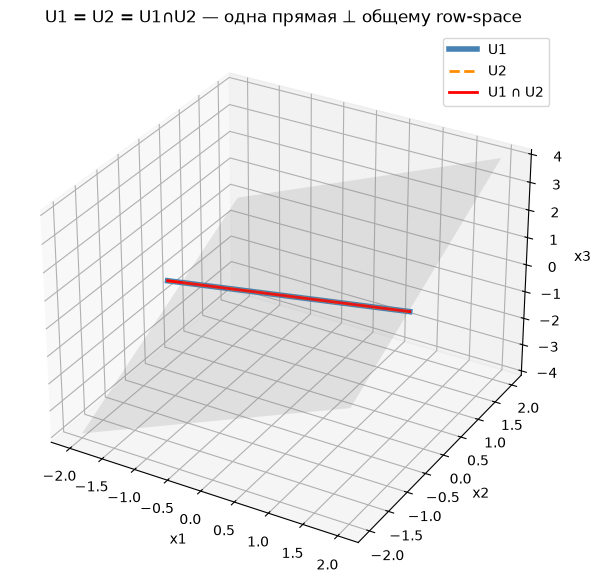

In [3]:
import numpy as np
import matplotlib.pyplot as plt

u = np.array([1, 1, -1], dtype=float); u /= np.linalg.norm(u)   # общее направление
p1 = np.array([1, 0, 1], dtype=float); p2 = np.array([0, 1, 1], dtype=float)  # базис row-space

fig = plt.figure(figsize=(7, 6))
ax = fig.add_subplot(111, projection='3d')

# плоскость пространства строк
g = np.linspace(-2, 2, 20); G1, G2 = np.meshgrid(g, g)
S = G1[..., None]*p1 + G2[..., None]*p2
ax.plot_surface(S[..., 0], S[..., 1], S[..., 2], alpha=0.18, color='gray')

# прямые
t = np.linspace(-2, 2, 2)
ax.plot(*( (t[:,None]*u).T ), lw=4, color='steelblue',  ls='-',  label='U1')
ax.plot(*( (t[:,None]*u).T ), lw=2, color='darkorange', ls='--', label='U2')
ax.plot(*( (t[:,None]*u).T ), lw=2, color='red',        ls='-',  label='U1 ∩ U2')

ax.set_xlabel('x1'); ax.set_ylabel('x2'); ax.set_zlabel('x3')
ax.set_title('U1 = U2 = U1∩U2 — одна прямая ⊥ общему row-space')
ax.legend(); plt.tight_layout(); plt.show()

## Проверка результата

В первой части размерности подтверждены теоремой о ранге и дефекте: численные ранги $A_1$ и $A_2$ равны 2, поэтому $\dim U_1=\dim U_2=1$; базисы получены из SVD и совпадают с направлением $(1,1,-1)^\top$, а пересечение найдено как ядро стопки $\begin{bmatrix}A_1\\A_2\end{bmatrix}$ — его размерность также 1, что согласуется с $\dim(U_1+U_2)=\dim U_1+\dim U_2-\dim(U_1\cap U_2)=1$. Прямая подстановка даёт $\|A_1 v\|=\|A_2 v\|\approx 0$, а равенство пространств строк объясняет, почему два разных набора уравнений задают одно и то же ядро. Во второй части проверка через псевдообратную матрицу показывает, что сдвиг решения вдоль направления ядра не меняет невязку $\|X\beta-y\|$, но увеличивает норму $\|\beta\|$, то есть ядро действительно кодирует неразличимые степени свободы модели.

## Вывод

Пространства решений однородных систем вычисляются как ядро матрицы, а их размерность определяется теоремой о ранге и дефекте; пересечение двух ядер сводится к ядру блочной матрицы из стопки строк. Продемонстрированы ключевые идеи главы — ранг, базис, ортогональность $\ker A=(\operatorname{row}A)^\perp$ — и важный феномен: разные матрицы могут задавать одно и то же подпространство решений, если совпадают их пространства строк. В машинном обучении этот аппарат описывает неразличимые направления параметров, минимально-нормальные решения через псевдообратную матрицу и согласованность латентных структур между различными представлениями данных.